# Retraining on the clean data: Effort

**Goal.** Ask the earlier questions again, on the features recomputed through the factor package's cleaning code (see
[ARCHITECTURE.md](../../ARCHITECTURE.md)): which preprocessing and model, how good, and does it meet the criteria. The rules were fixed
before any of this ran in [RETRAIN_PROTOCOL.md](../../RETRAIN_PROTOCOL.md); the decision rules and success criteria are the earlier protocol's own.

**Disclosure.** Each group was a test group once in the earlier experiments, scored on the old features with the same 20 labels. This
notebook scores them again on changed features. Every choice here is made on validation groups only, and the new test result is
reported **beside** the earlier one. It shows the effect of cleaning on the same 20 students, not fresh independent evidence.

**Data.** 144 real student-sprints (20 rated) plus 175 simulated student-sprints, **training only**: never validated, never tested, labels are
estimates from the label model.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("../../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import retrain as R
from core import GROUPS, group_bootstrap, load, make_splits, md_table, metrics, paired_diff_bootstrap
from retrain_configs import CONFIGS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

cfg = CONFIGS["effort"]()
F = cfg.factor()
RES = F.results
d = load(F)
real, sim = d[d.source == "real"], d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
LABEL, ACT = cfg.label, cfg.activity
print(cfg.title, "| real", len(real), "| rated", len(gold), "| simulated (training only)", len(sim))

Effort | real 144 | rated 20 | simulated (training only) 175


## 1. What cleaning changed in the data

In [2]:
old = pd.read_csv(Path("../dataset") / cfg.dataset_file, low_memory=False)
old = old[old.source == "real"].set_index("record_id")
cols = [c for c, _ in cfg.proposal]
rows = []
for c in cols:
    new_v = real.set_index("record_id")[c].astype(float)
    old_v = old[c].astype(float).reindex(new_v.index)
    ok = new_v.notna() & old_v.notna()
    rows.append({"feature": c, "median before": old_v.median(), "median now": new_v.median(),
                 "total now / before": new_v[ok].sum() / old_v[ok].sum() if old_v[ok].sum() else np.nan,
                 "rank agreement": new_v[ok].corr(old_v[ok], method="spearman")})
print("Real student-sprints: the proposal's features before and after cleaning")
display(pd.DataFrame(rows).set_index("feature").round(3))
rows = []
for c in cols:
    for name, frame in (("real", real), ("simulated", sim)):
        x = frame[c].astype(float).dropna()
        rows.append({"feature": c, "group": name, "p10": x.quantile(.1), "median": x.median(), "p90": x.quantile(.9), "missing": frame[c].isna().mean()})
print("Simulated students against real students (clean features)")
pd.DataFrame(rows).set_index(["feature", "group"]).round(3)

Real student-sprints: the proposal's features before and after cleaning


,median before,median now,total now / before,rank agreement
feature,,,,
E_CC,4.0,3.0,0.775,0.972
E_LOC_net_capped,868.5,730.5,0.799,0.964
E_FC,21.0,18.0,0.756,0.979
E_CT,1.0,1.0,1.000,1.000
E_RD,0.0,0.0,1.000,1.000


Simulated students against real students (clean features)


p10  median     p90  missing
feature          group                                  
E_CC             real       0.0     3.0    19.0      0.0
                 simulated  0.0     4.0    14.0      0.0
E_LOC_net_capped real       0.0   730.5  2934.3      0.0
                 simulated  0.0   721.0  2266.0      0.0
E_FC             real       0.0    18.0    64.2      0.0
                 simulated  0.0    10.0    20.0      0.0
E_CT             real       0.0     1.0     4.0      0.0
                 simulated  0.0     1.0     2.0      0.0
E_RD             real       0.0     0.0     0.0      0.0
                 simulated  0.0     0.0     7.0      0.0

## 2. Splits and baselines (validation)

In [3]:
splits = make_splits(d)
splits.to_csv(F.splits, index=False)
role = splits.join(d[["source", "label_source"]], on="record_id")
chk = role.groupby(["outer_test", "inner_val", "role"]).size().unstack(fill_value=0)
assert not ((role.role == "val") & (role.source == "synthetic")).any() and not ((role.role == "test") & (role.source == "synthetic")).any()
print("20 combinations; simulated rows are never in validation or test. Records per role (first rows):")
display(chk.head(8))
base = pd.read_csv(RES / "baseline_predictions.csv")
rows = []
for name, g in base.groupby("name"):
    m = metrics(g.y, g.pred)
    rows.append({"baseline": name, "MAE": m["MAE"], "pearson": m["pearson"], "spearman": m["spearman"], "bias": m["bias"]})
display(pd.DataFrame(rows).set_index("baseline").sort_values("MAE").round(3))

20 combinations; simulated rows are never in validation or test. Records per role (first rows):


role                  test  train  val
outer_test inner_val                  
A          B            71    220   28
           C            71    227   21
           D            71    232   16
           E            71    240    8
B          A            28    220   71
           C            28    270   21
           D            28    275   16
           E            28    283    8

,MAE,pearson,spearman,bias
baseline,,,,
ridge (5 proposal features),0.049,0.964,0.925,-0.011
"commit count (log, linear)",0.057,0.965,0.933,-0.014
tasks done (linear),0.101,0.885,0.819,-0.054
mean,0.248,-0.429,-0.385,-0.018
median,0.261,-0.332,-0.386,-0.020


## 3. Preprocessing: variants and label sources (Ridge, validation, selection without bias)

In [4]:
tuned = pd.read_csv(RES / "tuning_predictions.csv")
settings = json.load(open(RES / "settings.json"))
tuned.attrs["settings_path"] = str(RES / "settings.json")
rows = []
for (variant, lab, weight), g in tuned[tuned.model == "Ridge"].groupby(["variant", "lab", "weight"]):
    p, _ = R.bias_free(g)
    m = metrics(p.y, p.pred)
    rows.append({"variant": variant, "label source": lab, "weight": weight, "MAE": m["MAE"], "pearson": m["pearson"]})
prep = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
prep.round(3)

,variant,label source,weight,MAE,pearson
0,log5 (proposal),rated + propagated (real),0.3,0.046,0.967
1,log5 (proposal),rated + propagated (real),1.0,0.047,0.967
2,log5 (proposal),rated only,1.0,0.047,0.965
3,log5 (proposal),rated + propagated (real + synthetic),0.3,0.050,0.964
4,log5 (proposal),rated + propagated (real + synthetic),1.0,0.051,0.963
5,"log3 (commits, lines, files)",rated + propagated (real),0.3,0.061,0.946
6,"log3 (commits, lines, files)",rated + propagated (real),1.0,0.061,0.945
7,"log3 (commits, lines, files)",rated + propagated (real + synthetic),0.3,0.064,0.950
8,"log3 (commits, lines, files)",rated + propagated (real + synthetic),1.0,0.064,0.951
9,"log3 (commits, lines, files)",rated only,1.0,0.076,0.923


## 4. Ridge, Random Forest and Gradient Boosting, tuned, compared without selection bias

In [5]:
choice, table, pools, picks = R.decide(cfg, tuned, base, d, RES)
table.round(3)

,model,variant,MAE,bias,pearson,spearman
0,Random Forest,log5 (proposal),0.048,-0.014,0.966,0.934
1,Ridge,log5 (proposal),0.048,-0.004,0.965,0.921
2,Gradient Boosting,log5 (proposal),0.048,-0.005,0.962,0.932
3,"Ridge (rated only, LOO alpha)",proposal,0.049,-0.011,0.964,0.925
4,Ridge,"log3 (commits, lines, files)",0.065,-0.017,0.942,0.906
5,Random Forest,"log3 (commits, lines, files)",0.071,-0.014,0.922,0.880
6,Gradient Boosting,"log3 (commits, lines, files)",0.071,-0.006,0.924,0.887


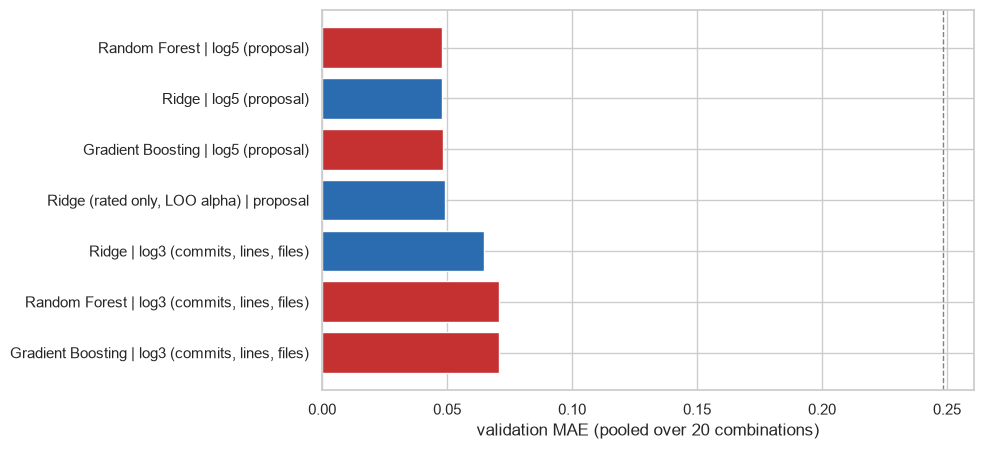

In [6]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(table) + 1.5))
labels = table.model + " | " + table.variant
ax.barh(labels[::-1], table.MAE[::-1], color=["#c53030" if "Forest" in l or "Boosting" in l else "#2b6cb0" for l in labels[::-1]])
for name, g in base.groupby("name"):
    if name in ("mean",):
        ax.axvline(metrics(g.y, g.pred)["MAE"], color="grey", ls="--", lw=1)
ax.set_xlabel("validation MAE (pooled over 20 combinations)")
fig.tight_layout(); plt.show()

## 5. The rule for keeping a complex model

In [7]:
rule = choice["rule"]
print(f"best Ridge-type model : {rule['ridge']}  (MAE {choice['ridge_best']['MAE']:.3f})")
print(f"best tree model       : {rule['complex']}  (MAE {choice['complex_best']['MAE']:.3f})")
print(f"gain {rule['gain_mae']:+.3f} MAE, 95% interval {rule['ci'][0]:+.3f} to {rule['ci'][1]:+.3f}, better in {rule['folds_better']} of 5 folds")
# provisional choice by rules 1-3; rule 4 (invariants) is checked in section 6 on the fitted fold models
chosen_name = choice["complex_best"]["model"] if rule["passes_1_3"] else choice["ridge_best"]["model"]
chosen_variant = choice["complex_best"]["variant"] if rule["passes_1_3"] else choice["ridge_best"]["variant"]
ridge_name, ridge_variant = choice["ridge_best"]["model"], choice["ridge_best"]["variant"]
print("provisional model:", chosen_name, "|", chosen_variant)

best Ridge-type model : Ridge | log5 (proposal)  (MAE 0.048)
best tree model       : Random Forest | log5 (proposal)  (MAE 0.048)
gain +0.000 MAE, 95% interval -0.013 to +0.025, better in 1 of 5 folds
provisional model: Ridge | log5 (proposal)


## 6. Effort only: invariants and the guard layer (rule 4)

In [8]:
final_all, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings,
                               extra_models=[(ridge_name, ridge_variant)])
rows = []
for (model, variant) in sorted({(m, v) for (m, v, _) in fits}):
    for guarded in (False, True):
        z, mo, sp, t = R.effort_invariants(fits, model, variant, guarded)
        rows.append({"model": f"{model} | {variant}", "guard": guarded, "zero commits ~ 0": z, "never lowered by more": mo, "spam and dump <= 0.35": sp})
inv = pd.DataFrame(rows)
display(inv)
z, mo, sp, t = R.effort_invariants(fits, chosen_name, chosen_variant, True)
display(t.round(3))

,model,guard,zero commits ~ 0,never lowered by more,spam and dump <= 0.35
0,Ridge | log5 (proposal),False,True,True,False
1,Ridge | log5 (proposal),True,True,True,True


,mean score,min over folds,max over folds
zero commits,0.000,0.000,0.000
micro-commit spam,0.219,0.215,0.228
library dump,0.255,0.234,0.286
one huge commit,0.334,0.312,0.363
many tiny real commits,0.485,0.474,0.492
typical active student,0.452,0.444,0.456
heavy contributor,0.831,0.798,0.862
largest drop when one count rises,0.000,0.000,0.000


In [9]:
# rule 4: a complex model replaces Ridge only if it passes every invariant that Ridge passes (with the guard, the pipeline's form)
def passes(model, variant):
    z, mo, sp, _ = R.effort_invariants(fits, model, variant, True)
    return z and mo and sp
if chosen_name != ridge_name and not (passes(chosen_name, chosen_variant) or not passes(ridge_name, ridge_variant)):
    print("the tree model fails an invariant that Ridge passes: Ridge is kept")
    chosen_name, chosen_variant = ridge_name, ridge_variant
print("model for the final test:", chosen_name, "|", chosen_variant)
json.dump({**choice, "chosen": [chosen_name, chosen_variant]}, open(RES / "model_choice.json", "w"), indent=1, default=float)

model for the final test: Ridge | log5 (proposal)


## 7. Final test, scored once

In [10]:
final, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings)
final.to_csv(RES / "final_test_predictions_unguarded.csv", index=False)
MAIN = f"{chosen_name} | {chosen_variant}"
GUARDED = MAIN + " + guard"
fg = final[final.name == MAIN].copy()
fg["name"] = GUARDED
fg["pred"] = np.concatenate([R.predict_with(fits[(chosen_name, chosen_variant, o)], d.loc[fg[fg.outer_test == o].record_id], True) for o in GROUPS])
final = pd.concat([final, fg], ignore_index=True)
final.to_csv(RES / "final_test_predictions.csv", index=False)
print("the pipeline's form is the guarded one (protocol); unguarded results are in the table below")
MAIN = GUARDED
fold_info = pd.DataFrame({o: fits[(chosen_name, chosen_variant, o)][2] for o in GROUPS}).T
display(fold_info)
print(len(final[final.name == MAIN]), "test predictions from", len(GROUPS), "models, each made by a model that never saw that student")

the pipeline's form is the guarded one (protocol); unguarded results are in the table below


,label_config,alpha
A,rated only (weight 1.0),3.162278
B,rated only (weight 1.0),3.162278
C,rated only (weight 1.0),3.162278
D,rated only (weight 1.0),1.0
E,rated only (weight 1.0),3.162278


20 test predictions from 5 models, each made by a model that never saw that student


In [11]:
crit, m = R.criteria_table(cfg, final, MAIN, d)
crit.to_csv(RES / "final_test_criteria.csv", index=False)
display(crit.round(3))

,criterion,value,minimum,target,verdict,note
0,MAE,0.058995,<= 0.11,<= 0.08,target met,95% interval 0.038-0.075
1,Pearson and Spearman,0.952 / 0.900,>= 0.8 both,>= 0.9 / 0.85,target met,
2,"Beats commit count (log, linear)",gain -0.002 (-3%),interval of the gain excludes 0,>= 10% lower,NOT MET,95% interval -0.008 to +0.004
3,Bias,-0.008377,within +-0.05,within +-0.03,target met,
4,Calibration slope,0.986846,0.7-1.3,0.8-1.2,target met,
5,Rubric bands within one,1.0,>= 85%,">= 90%, exact >= 50%",target met,exact 80%
6,"MAE, students with activity",0.06866,<= 0.12,<= 0.1,target met,n = 15


,MAE,pearson,spearman,bias
model,,,,
Ridge | log5 (proposal),0.053,0.959,0.915,0.008
"commit count (log, linear)",0.057,0.966,0.933,-0.014
Ridge | log5 (proposal) + guard,0.059,0.952,0.900,-0.008
tasks done (linear),0.100,0.892,0.811,-0.051
median,0.210,-0.469,-0.485,0.038
mean,0.239,-0.739,-0.646,-0.013


outer_test,A,B,C,D,E
n,7.000,4.000,4.00,3.000,2.0
MAE,0.065,0.063,0.05,0.091,0.0


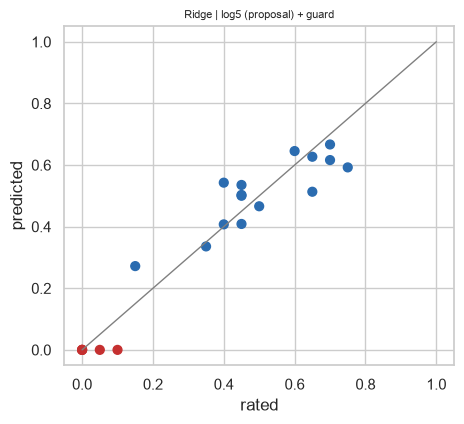

In [12]:
rows = []
for name, g in final.groupby("name"):
    mm = metrics(g.y, g.pred)
    rows.append({"model": name, "MAE": mm["MAE"], "pearson": mm["pearson"], "spearman": mm["spearman"], "bias": mm["bias"]})
display(pd.DataFrame(rows).set_index("model").sort_values("MAE").round(3))
pf = final[final.name == MAIN].assign(err=lambda x: (x.pred - x.y).abs())
display(pf.groupby("outer_test").agg(n=("err", "size"), MAE=("err", "mean")).round(3).T)
f = final[final.name == MAIN]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(f.y, f.pred, c=np.where(f.activity > 0, "#2b6cb0", "#c53030"), s=40)
ax.plot([0, 1], [0, 1], color="grey", lw=1)
ax.set_xlabel("rated"); ax.set_ylabel("predicted"); ax.set_title(MAIN, fontsize=8)
fig.tight_layout(); plt.show()

## 8. Beside the earlier result (old features, same 20 students)

In [13]:
oldp = pd.read_csv(Path("../training/results/final_test_predictions.csv"))
mo, mn = metrics(oldp.y, oldp.pred), metrics(f.y, f.pred)
cmp = pd.DataFrame({"earlier (old features)": mo, "now (clean features)": mn}).loc[["n", "MAE", "RMSE", "bias", "pearson", "spearman", "calib_slope", "band_within_1", "band_exact"]]
display(cmp.round(3))
oldc = pd.read_csv(Path("../training/results/final_test_criteria.csv"))
print("Earlier criteria table (old features):")
display(oldc)

,earlier (old features),now (clean features)
n,20.000,20.000
MAE,0.069,0.059
RMSE,0.096,0.077
bias,-0.010,-0.008
pearson,0.931,0.952
spearman,0.931,0.900
calib_slope,1.153,0.987
band_within_1,1.000,1.000
band_exact,0.550,0.800


Earlier criteria table (old features):


,criterion,result,minimum (works),target,meets minimum,meets target
0,MAE,0.069,<= 0.11,<= 0.08,True,True
1,Pearson,0.931,>= 0.80,>= 0.90,True,True
2,Spearman,0.931,>= 0.80,>= 0.85,True,True
3,Beats commit count alone,gain -0.015 (95% CI -0.052 to 0.011),interval excludes 0,and >= 10% lower MAE,False,False
4,Bias,-0.010,within +-0.05,within +-0.03,True,True
5,Calibration slope,1.15,0.7 - 1.3,0.8 - 1.2,True,True
6,Rubric bands within one,100%,>= 85%,>= 90%,True,True
7,Rubric bands exact,55%,-,>= 50%,True,True
8,"MAE, records with activity",0.081,<= 0.12,<= 0.10,True,True


## 9. Reading the results

_Reading of the results: written after the run._